# Setup


In [3]:
# imports
import numpy as np
from scipy.stats import norm
from scipy.integrate import quad
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import __version__ as sklearn_version
import pandas as pd
import joblib
from joblib import Parallel, delayed

###### D1 
# true values
theta0 = 3.0 # true att following chang to rep results
s = 5 # number of true non-zero params
gamma_main = np.array([5,4,3,2,1])/s # following chang
c_penalty = 1.1 # c in plug-in penalty following belloni et al. 
alpha_penalty = 0.05 # significance level for plug-in penalty
refine_N = 1
k_folds = 5
clip =(0.03, 0.97)
seed = 666
n_test = 5000   

###### D2/D3
theta0_d23 = 1.0 # true att
cells_d23 = [(0.7, 0.7), (2.0, 2.0), (0.8, 1.5)] # three regimes for decay rates
signs_d23 = ("aligned", "random") # ctrl sign of error. same sign = D2, random = D3
p_max = 2000  # p at the largest N (N = 4000, p = N/2)
R = 200

###### D4
theta0_d4 = 1.0  # true att in D4
a0_d4 = -0.25  # lgit intercept

In [4]:
# a.logit function
def logit(x):
    return 1/(1+np.exp(-x))

# b. plug in penalty for lasso following Belloni et al. (2012)
def plugin_penalty(p):
    return norm.ppf(1-alpha_penalty/(2*p)) # b1. only the inverse part of the peanalty

# c. standardizing function for lasso
def standardize(X):
    mean =X.mean(axis=0)
    sd = X.std(axis=0)
    sd[sd==0] = 1.0 # c1. constant column in case a category is missing
    return (X - mean)/sd

# d. intercept - coef /sd*mean,
def raw_scale(intercept, coef_std, mean, sd):
    coef = coef_std/sd
    return intercept-coef @mean, coef

FORCE = 100.0      # forced-in columns get 1/100 of the penalty: effectively unpenalised

# e. propensity fit
def fit_propensity(X, D, unpen=()):
    n, p = X.shape
    unpen = np.asarray(unpen, dtype=int)
    mean, sd = X.mean(axis=0), X.std(axis=0)
    sd[sd == 0] = 1.0                                   # constant column
    Z = (X - mean)/sd                                   # standardise
    scale = np.ones(p)
    scale[unpen] = FORCE                                # forced-in columns: 1/100 of the penalty
    lam = c_penalty*plugin_penalty(p)/(2*np.sqrt(n))
    C = 1/(n*lam)
    model = LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=20000)   # as in your runs
    model.fit(Z*scale, D)
    coef_std = model.coef_[0]*scale                     # back to the standardised scale
    b0, b = raw_scale(model.intercept_[0], coef_std, mean, sd)   # FIX: mean and sd of X, not of Z
    S = np.union1d(np.flatnonzero(coef_std), unpen).astype(int)  # forced-in columns always selected

    # post-lasso refit
    b_post = np.zeros(p)
    if len(S) > 0:
        refit = LogisticRegression(C=1e4, max_iter=5000).fit(X[:, S], D)
        b0_post = refit.intercept_[0]
        b_post[S] = refit.coef_[0]
    else:
        b0_post = np.log(D.mean()/(1 - D.mean()))
    return {"lasso": (b0, b), "post": (b0_post, b_post), "selected": S}


# f. outcome regression
def fit_outcome(X, y, unpen=()):
    n, p = X.shape
    unpen = np.asarray(unpen, dtype=int)
    mean, sd = X.mean(axis=0), X.std(axis=0)
    sd[sd == 0] = 1.0                                   # FIX: the same guard as in standardize
    Z = (X - mean)/sd
    lam = 2*c_penalty*plugin_penalty(p)/np.sqrt(n)
    resid = y - y.mean()
    for step in range(1 + refine_N):
        psi = np.sqrt(np.mean(Z**2*resid[:, None]**2, axis=0))
        psi[psi == 0] = 1.0
        psi[unpen] = psi[unpen]/FORCE                   # forced-in columns: tiny loading
        Zs = Z/psi
        fit = Lasso(alpha=lam/2, max_iter=50000).fit(Zs, y)      # as in your runs
        resid = y - fit.predict(Zs)
    coef_std = fit.coef_/psi
    S = np.union1d(np.flatnonzero(coef_std), unpen).astype(int)
    b0, b = raw_scale(fit.intercept_, coef_std, mean, sd)

    # post-lasso
    A = np.column_stack([np.ones(n), X[:, S]])
    post = np.linalg.lstsq(A, y, rcond=None)[0]
    b_post = np.zeros(p)
    b_post[S] = post[1:]
    return {"lasso": (b0, b), "post": (post[0], b_post), "selected": S}


# h. fitting nuisances on the auxiliary sample
def cross_fit(X, D, dY, folds, unpen=()):
    fits = []
    for k, ev in enumerate(folds):
        auxiliary = np.concatenate([f for j, f in enumerate(folds) if j != k])   # I_k^c
        fg = fit_propensity(X[auxiliary], D[auxiliary], unpen)
        ctrl = auxiliary[D[auxiliary] == 0]
        fl = fit_outcome(X[ctrl], dY[ctrl], unpen)
        fits.append({"ev": ev, "g": fg, "l": fl, "p_hat": D[ev].mean()})   # p_hat on the fold
    return fits

# g. 
def make_folds(N, K, rng):
    return np.array_split(rng.permutation(N), K) # g1. random split of N-1 rows into K folds of eq size. gives array w row numbers


# i. dml_did 
def dml_did(X, D, dY, fits, kind):
    parts = []
    for f in fits: # i1. loop over the fold fits
        ev = f["ev"]
        b0, b = f["g"][kind] # i2. coef on 
        g = np.clip(logit(b0 + X[ev] @ b),*clip) #i3. fitted prop score on fold. NB! clip is set to (0,03-0,97) like chang
        a0, a = f["l"][kind]
        l = a0 + X[ev] @ a # i4. fitted trend on fold
        parts.append((ev, g, l, f["p_hat"]))

    # i5. calculate theta tilde k: the score averaged 
    # over fold k; tilde k the average over folds 
    theta_k = [np.mean((dY[ev] - l)*(D[ev] - g)/(p_hat*(1 - g)))
               for ev, g, l, p_hat in parts] # i6. 1/n*sum(Y1-Y0-ell_k)*(hat(p)_k-g_k)/(hat(p)_k*(1-g_k))
    theta = np.mean(theta_k) # i7. final estimator 

    # i8. calculate variance, psi_1= (dY - ell)*(hat(p)_k-g_k)/denom-theta
    sigma2 = np.mean(np.concatenate([
        ((dY[ev] - l)*(D[ev] - g)/(p_hat*(1 - g)) - theta
         - theta/p_hat*(D[ev] - p_hat))**2 # i9.correction term
        for ev, g, l, p_hat in parts]))
    return theta, np.sqrt(sigma2/len(D))  # i10. extract estimator and std error

# j. oracle estimator as bm. 
def oracle(D, dY, g0, l10):
    p_hat = D.mean()
    score = (dY-l10)*(D-g0)/(p_hat*(1-g0))
    theta = score.mean()
    sigma2 = np.mean((score-theta-theta/p_hat*(D-p_hat))**2)
    return theta, np.sqrt(sigma2/len(D)) #j1. since all is calculayed on true cals, only error can be sampling error

# k. unadjusted abadie DiD
def unadjusted(D, dY):
    t = dY[D == 1] # k1. chnage in outcome for treated units
    c=dY[D == 0] # k2. change -...- for UNtreated
    return t.mean() - c.mean(), np.sqrt(t.var(ddof=1)/len(t) + c.var(ddof=1)/len(c))
# k3. difference in means, standard error on estimate

# l. IPW estimator with lasso propensity
def abadie_plugin(X, D, dY):
    fg = fit_propensity(X, D)
    b0, b = fg["lasso"]
    g = np.clip(logit(b0 + X @ b),*clip)
    return np.mean(dY*(D - g)/(D.mean()*(1 - g)))
# l1. no standard error bc abadie's is for low-dim regime?

#m. coefs
def coefs(p):
    gamma = np.zeros(p) 
    gamma[:s] = gamma_main # m1. choose the propensity index
    delta = gamma.copy() # m2. untreated trend
    beta = gamma + 0.5 # m3. chang's level coefs
    return gamma, delta, beta

# n. for bias formula
def make_test_draw(p, trend, seed):
    gamma, delta, _ = coefs(p) # 
    rng_test = np.random.default_rng([seed, 999, p]) # m2. make random draw of X 
    X = rng_test.standard_normal((n_test, p))
    g_0 = logit(X @ gamma) # m3. "true" prop score in random draw
    l10 = 1.0 + X @ delta if trend else np.ones(n_test) # m4. either constant or fitted function. 1.0 is the common trend 
    return {"X": X, "g_0": g_0, "l10": l10}

# n. bias 
def B1(fits, test, kind):
    X, g_0, l10 = test["X"], test["g_0"], test["l10"]
    p0 = g_0.mean()  # n1. true treated share
    vals = []
    for f in fits: # n2. loop over k folds
        b0, b = f["g"][kind]
        g = np.clip(logit(b0 + X @ b),*clip) 
        a0, a = f["l"][kind]
        l = a0 + X @ a
        vals.append(np.mean((l - l10)*(g - g_0)/(p0*(1 - g))))
    return np.mean(vals)  

# Data-generating process (d1)

I'm simulating a well-behaved covariate distribution, $$ X \sim N(0, I_p) $$

In [5]:
# a. simulate D1
def simulate_d1(N, p, 
                trend, rng, 
                sd_e1=0.1, sd_e2=None, sd_e3=0.1):
    gamma, delta, beta = coefs(p) 
    # a1. trend version, var(X'delta)
    if sd_e2 is None: 
        sd_e2 = np.sqrt(delta @ delta) if trend else 0.1
    X = rng.standard_normal(size=(N, p)) 
    g_0 = logit(X @ gamma) 
    D = rng.binomial(1, g_0).astype(float) # a2. treatment status
    l10 = 1.0 + X @ delta if trend else np.ones(N) 

    # a3. potential outcomes
    y00= X @ beta + sd_e1*rng.standard_normal(size=N) # a4. untreated, period 0
    y01= y00+ l10 + sd_e2*rng.standard_normal(size=N) # a5. untreated, period 1
    y11= y01 + theta0 + sd_e3*rng.standard_normal(size=N) # a6. treated, period 1
    y0 = y00 # a7. observed outcome in period 0
    y1 = np.where(D==1, y11, y01) # a8.observed outcome in period 1
    return { "X": X, "D": D, "y0": y0, "y1": y1, "g_0": g_0, "l10": l10, "dY": y1 - y0 }

#b. 
def pop_values(p, trend):
    gamma, delta, _ = coefs(p) # b1. exclude chang's level coefs
    sd_index = np.sqrt(gamma @gamma) # b2. standard error of propensity index
    density = lambda z: norm.pdf(z, scale= sd_index) #b3.
    p0 = quad(lambda z: logit(z)*density(z), -np.inf, np.inf)[0] # b4. integrate log(index)*\phi(index)
    e_dlam = quad(lambda z: logit(z)*(1-logit(z))*density(z), -np.inf, np.inf)[0] # b5.integral differentiated
    gd = gamma @ delta if trend else 0.0
    return p0,e_dlam*gd/(p0*(1-p0))

for trend in (False, True): # b6. for both trend and non-trend
    p0, bias_pop = pop_values(p=100, trend=trend)
    rng = np.random.default_rng(seed)
    big = simulate_d1(N=200000, p=10, trend=trend, rng=rng)
    D= big["D"]
    dY = big["dY"]
    unadj_bias = dY[D == 1].mean() - dY[D == 0].mean() - theta0
    print(f"trend={trend}: p0 = {p0:.3f} (sample {D.mean():.3f}), "
          f"unadjusted bias = {bias_pop:.3f} (sample {unadj_bias:.3f})")

C:\Users\annal\AppData\Local\Temp\ipykernel_22244\2127513477.py:3: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-x))


trend=False: p0 = 0.500 (sample 0.501), unadjusted bias = 0.000 (sample -0.001)
trend=True: p0 = 0.500 (sample 0.501), unadjusted bias = 1.563 (sample 1.555)


run with plugin

In [6]:
rng = np.random.default_rng(seed)
for N in (200, 1000, 2000):
    data = simulate_d1(N=N, p=N // 2, trend=True, rng=rng)
    X, D, dY = data["X"], data["D"], data["dY"]
    fg = fit_propensity(X, D)
    ctrl = D == 0
    fl = fit_outcome(X[ctrl], dY[ctrl])
    print(f"N={N}: propensity selects {fg['selected'][:10]}, outcome selects {fl['selected'][:10]}, "
          f"post-Lasso trend coefs {np.round(fl['post'][1][:5], 2)}")

N=200: propensity selects [1], outcome selects [0], post-Lasso trend coefs [0.98 0.   0.   0.   0.  ]
N=1000: propensity selects [0 1 2 3], outcome selects [0 1 2], post-Lasso trend coefs [0.9  0.82 0.53 0.   0.  ]
N=2000: propensity selects [0 1 2 3], outcome selects [0 1 2 3], post-Lasso trend coefs [0.97 0.76 0.6  0.36 0.  ]


# cross-fitting and DML-DiD


In [7]:
rng = np.random.default_rng(seed)
for N in (200, 1000, 2000):
    data = simulate_d1(N=N, p=N // 2, trend=True, rng=rng)
    X, D, dY = data["X"], data["D"], data["dY"]
    folds = make_folds(N, k_folds, rng)
    fits = cross_fit(X, D, dY, folds)
    for kind in ("post", "lasso"):
        th, se = dml_did(X, D, dY, fits, kind)
        print(f"N={N} {kind:5s}: theta = {th:.3f}, se = {se:.3f}")
    print("        unadjusted:", round(dY[D == 1].mean() - dY[D == 0].mean(), 3))

N=200 post : theta = 4.400, se = 0.345
N=200 lasso: theta = 4.976, se = 0.310
        unadjusted: 4.841
N=1000 post : theta = 3.317, se = 0.124
N=1000 lasso: theta = 4.079, se = 0.109
        unadjusted: 4.657
N=2000 post : theta = 2.769, se = 0.177
N=2000 lasso: theta = 3.447, se = 0.097
        unadjusted: 4.631


run with oracle and abadie

In [8]:
rng = np.random.default_rng(seed)
for trend in (False, True):
    for N in (200, 2000):
        data = simulate_d1(N=N, p=N // 2, trend=trend, rng=rng)
        X, D, dY = data["X"], data["D"], data["dY"]
        o = oracle(D, dY, data["g_0"], data["l10"])
        u = unadjusted(D, dY)
        a = abadie_plugin(X, D, dY)
        print(f"trend={trend} N={N}: oracle {o[0]:.3f} ({o[1]:.3f}), "
              f"unadjusted {u[0]:.3f} ({u[1]:.3f}), Abadie plug-in {a:.3f}")

trend=False N=200: oracle 3.024 (0.025), unadjusted 3.011 (0.017), Abadie plug-in 3.037
trend=False N=2000: oracle 3.000 (0.009), unadjusted 2.994 (0.006), Abadie plug-in 3.145
trend=True N=200: oracle 2.950 (0.346), unadjusted 4.603 (0.292), Abadie plug-in 4.392
trend=True N=2000: oracle 3.005 (0.088), unadjusted 4.678 (0.088), Abadie plug-in 4.076


In [9]:
for k, f in enumerate(fits):
    ev = f["ev"]
    ctrl_ev = D[ev] == 0
    for kind in ("post", "lasso"):
        b0, b = f["g"][kind]
        g = np.clip(logit(b0 + X[ev] @ b),*clip)
        w = g/(1 - g)                                   # a control's weight in the score
        print(f"fold {k} {kind:5s}: selected {f['g']['selected']}, "
              f"g in [{g.min():.3f}, {g.max():.3f}], "
              f"clipped {np.mean((g <= clip[0]) | (g >= clip[1])):.1%}, "
              f"max control weight {w[ctrl_ev].max():.1f}")

fold 0 post : selected [0 1 2 3], g in [0.030, 0.970], clipped 3.8%, max control weight 12.7
fold 0 lasso: selected [0 1 2 3], g in [0.050, 0.910], clipped 0.0%, max control weight 3.9
fold 1 post : selected [0 1 2 3], g in [0.030, 0.970], clipped 2.2%, max control weight 8.8
fold 1 lasso: selected [0 1 2 3], g in [0.075, 0.934], clipped 0.0%, max control weight 2.9
fold 2 post : selected [0 1 2 3], g in [0.030, 0.970], clipped 2.0%, max control weight 23.1
fold 2 lasso: selected [0 1 2 3], g in [0.118, 0.924], clipped 0.0%, max control weight 4.7
fold 3 post : selected [0 1 2 3], g in [0.030, 0.970], clipped 3.0%, max control weight 19.8
fold 3 lasso: selected [0 1 2 3], g in [0.129, 0.880], clipped 0.0%, max control weight 3.5
fold 4 post : selected [0 1 2 3], g in [0.030, 0.970], clipped 3.2%, max control weight 9.6
fold 4 lasso: selected [0 1 2 3], g in [0.104, 0.938], clipped 0.0%, max control weight 3.9


bias in lasso and post laaso

In [10]:
rng = np.random.default_rng(seed)
N, r_test = 200, 20
test = make_test_draw(p=N // 2, trend=True, seed=seed)
res = {kind: ([], []) for kind in ("post", "lasso")}
for r in range(r_test):
    data = simulate_d1(N=N, p=N // 2, trend=True, rng=rng)
    X, D, dY = data["X"], data["D"], data["dY"]
    fits = cross_fit(X, D, dY, make_folds(N, k_folds, rng))
    for kind in ("post", "lasso"):
        th, se = dml_did(X, D, dY, fits, kind)
        res[kind][0].append(th - theta0)
        res[kind][1].append(B1(fits, test, kind))

for kind, (err, b1) in res.items():
    print(f"{kind:5s}: mean(theta - theta0) = {np.mean(err):.3f} "
          f"(MCSE {np.std(err, ddof=1)/np.sqrt(r_test):.3f}), mean B1 = {np.mean(b1):.3f}")

post : mean(theta - theta0) = 0.580 (MCSE 0.175), mean B1 = 0.634
lasso: mean(theta - theta0) = 1.418 (MCSE 0.068), mean B1 = 1.432


In [11]:
def one_replication(N, p, trend, K, rng, test):
    """Everything for one simulated data set; returns one row of results."""
    data = simulate_d1(N=N, p=p, trend=trend, rng=rng)
    X, D, dY = data["X"], data["D"], data["dY"]
    folds = make_folds(N, K, rng)                 # drawn AFTER the data
    fits = cross_fit(X, D, dY, folds)
    out = {}
    for kind in ("post", "lasso"):
        out[f"theta_{kind}"], out[f"se_{kind}"] = dml_did(X, D, dY, fits, kind)
        out[f"B1_{kind}"] = B1(fits, test, kind)
    out["theta_oracle"], out["se_oracle"] = oracle(D, dY, data["g_0"], data["l10"])
    out["theta_unadj"], out["se_unadj"] = unadjusted(D, dY)
    out["theta_abadie"] = abadie_plugin(X, D, dY)
    out["sel_g"] = np.mean([len(f["g"]["selected"]) for f in fits])            # selected, propensity
    out["sel_l"] = np.mean([len(f["l"]["selected"]) for f in fits])            # selected, trend
    out["sel_l_true"] = np.mean([np.sum(f["l"]["selected"] < s) for f in fits])  # ...of which true
    return out


def run_cell(N, p, trend, K, R, seed):
    test = make_test_draw(p, trend, seed)
    children = np.random.SeedSequence([seed, N, int(trend)]).spawn(R)
    rows = [one_replication(N, p, trend, K, np.random.default_rng(child), test)
            for child in children]
    return pd.DataFrame(rows)


def summarize(df, theta0, kinds=("post", "lasso", "oracle", "unadj", "abadie")):
    """Bias, MCSE, SD, robust SD, RMSE, coverage, SE/SD and mean B1 per estimator."""
    R = len(df)
    table = {}
    for k in kinds:
        est = df[f"theta_{k}"]
        q25, q75 = est.quantile([0.25, 0.75])
        row = {"bias": est.mean() - theta0,
               "MCSE": est.std(ddof=1)/np.sqrt(R),
               "SD": est.std(ddof=1),
               "SD robust": (q75 - q25)/1.349,
               "RMSE": np.sqrt(np.mean((est - theta0)**2))}
        if f"se_{k}" in df:
            se = df[f"se_{k}"]
            cover = np.mean(np.abs(est - theta0) <= 1.96*se)
            row["coverage"] = cover
            row["cov MCSE"] = np.sqrt(cover*(1 - cover)/R)
            row["SE/SD"] = se.mean()/est.std(ddof=1)
        if f"B1_{k}" in df:
            row["B1"] = df[f"B1_{k}"].mean()
        table[k] = row
    return pd.DataFrame(table).T

In [12]:
R = 500
designs = [dict(N=200, p=100, trend=False, K=2),
           dict(N=200, p=100, trend=False, K=5)] + \
          [dict(N=N, p=N // 2, trend=True, K=5) for N in (200, 1000, 2000)]

results = {}
for d in designs:
    df = run_cell(**d, R=R, seed=seed)
    name = f"d1_N{d['N']}_trend{int(d['trend'])}_K{d['K']}"
    df.to_csv(name + ".csv", index=False)       # raw results: never rerun to re-summarise
    results[name] = df
    print(name)
    print(summarize(df, theta0).round(3).to_string())

d1_N200_trend0_K2
         bias   MCSE     SD  SD robust   RMSE  coverage  cov MCSE  SE/SD   B1
post   -0.000  0.001  0.024      0.022  0.024     0.960     0.009  0.961  0.0
lasso   0.000  0.001  0.018      0.019  0.018     0.948     0.010  0.983  0.0
oracle  0.000  0.001  0.027      0.024  0.027     0.946     0.010  0.900  NaN
unadj   0.000  0.001  0.017      0.019  0.017     0.948     0.010  1.009  NaN
abadie  0.071  0.002  0.042      0.041  0.082       NaN       NaN    NaN  NaN
d1_N200_trend0_K5
         bias   MCSE     SD  SD robust   RMSE  coverage  cov MCSE  SE/SD   B1
post    0.000  0.001  0.025      0.023  0.025     0.956     0.009  0.960  0.0
lasso   0.000  0.001  0.018      0.018  0.018     0.958     0.009  1.007 -0.0
oracle  0.000  0.001  0.027      0.024  0.027     0.946     0.010  0.900  NaN
unadj   0.000  0.001  0.017      0.019  0.017     0.948     0.010  1.009  NaN
abadie  0.071  0.002  0.041      0.041  0.082       NaN       NaN    NaN  NaN
d1_N200_trend1_K5
         b

In [13]:
estimators = [("post", "DML-DiD, post-Lasso"), ("lasso", "DML-DiD, Lasso (no refit)"),
              ("oracle", "Oracle"), ("unadj", "Unadjusted DiD"), ("abadie", "Abadie, plug-in Lasso")]
cells = [("d1_N200_trend0_K2", r"Chang's design, $N=200$, $K=2$"),
         ("d1_N200_trend0_K5", r"Chang's design, $N=200$, $K=5$"),
         ("d1_N200_trend1_K5", r"Trend version, $N=200$"),
         ("d1_N1000_trend1_K5", r"Trend version, $N=1000$"),
         ("d1_N2000_trend1_K5", r"Trend version, $N=2000$")]


def fmt(x, d=3):
    """Number with d decimals; LaTeX minus sign; dash if missing."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "--"
    if round(x, d) == 0:
        x = 0.0                            # avoid printing "-0.000"
    s = f"{x:.{d}f}"
    return ("$-$" + s[1:]) if s.startswith("-") else s


lines = [r"\begin{tabular}{l rr rr r r r}", r"\toprule",
         r" & Bias & MCSE & SD & Robust SD & SE/SD & Coverage & $B_1$ \\", r"\midrule"]
for i, (name, title) in enumerate(cells):
    df = pd.read_csv(name + ".csv")
    R = len(df)
    extra = ""
    if "trend1" in name:
        extra = f"; outcome Lasso selects {df['sel_l_true'].mean():.2f} of the 5 trend coefficients"
    if i > 0:
        lines.append(r"\addlinespace")
    lines.append(rf"\multicolumn{{8}}{{l}}{{\emph{{{title}{extra}}}}} \\")
    for k, label in estimators:
        if "trend0" in name and k == "abadie" and "K5" in name:
            continue                       # Abadie does not use folds: same as the K = 2 row
        est = df[f"theta_{k}"]
        q25, q75 = est.quantile([0.25, 0.75])
        row = [est.mean() - theta0, est.std(ddof=1) / np.sqrt(R), est.std(ddof=1), (q75 - q25) / 1.349]
        if f"se_{k}" in df:
            se = df[f"se_{k}"]
            row += [se.mean() / est.std(ddof=1), np.mean(np.abs(est - theta0) <= 1.96 * se)]
        else:
            row += [np.nan, np.nan]
        row.append(df[f"B1_{k}"].mean() if f"B1_{k}" in df else np.nan)
        cells_txt = [fmt(row[0]), fmt(row[1]), fmt(row[2]), fmt(row[3]), fmt(row[4], 2), fmt(row[5], 3), fmt(row[6])]
        lines.append(rf"\quad {label} & " + " & ".join(cells_txt) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
open("d1_table.tex", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

\begin{tabular}{l rr rr r r r}
\toprule
 & Bias & MCSE & SD & Robust SD & SE/SD & Coverage & $B_1$ \\
\midrule
\multicolumn{8}{l}{\emph{Chang's design, $N=200$, $K=2$}} \\
\quad DML-DiD, post-Lasso & 0.000 & 0.001 & 0.024 & 0.022 & 0.96 & 0.960 & 0.000 \\
\quad DML-DiD, Lasso (no refit) & 0.000 & 0.001 & 0.018 & 0.019 & 0.98 & 0.948 & 0.000 \\
\quad Oracle & 0.000 & 0.001 & 0.027 & 0.024 & 0.90 & 0.946 & -- \\
\quad Unadjusted DiD & 0.000 & 0.001 & 0.017 & 0.019 & 1.01 & 0.948 & -- \\
\quad Abadie, plug-in Lasso & 0.071 & 0.002 & 0.042 & 0.041 & -- & -- & -- \\
\addlinespace
\multicolumn{8}{l}{\emph{Chang's design, $N=200$, $K=5$}} \\
\quad DML-DiD, post-Lasso & 0.000 & 0.001 & 0.025 & 0.023 & 0.96 & 0.956 & 0.000 \\
\quad DML-DiD, Lasso (no refit) & 0.000 & 0.001 & 0.018 & 0.018 & 1.01 & 0.958 & 0.000 \\
\quad Oracle & 0.000 & 0.001 & 0.027 & 0.024 & 0.90 & 0.946 & -- \\
\quad Unadjusted DiD & 0.000 & 0.001 & 0.017 & 0.019 & 1.01 & 0.948 & -- \\
\addlinespace
\multicolumn{8}{l}{\emph{

NameError: name 'BLUE' is not defined

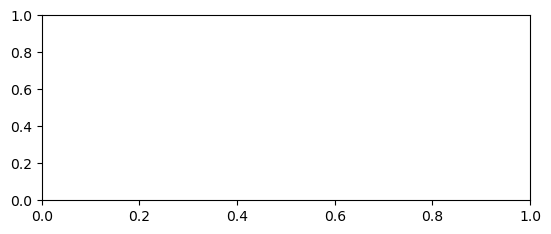

In [14]:
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

def density(ax, x, lo, hi, color, label):
    """Kernel density estimate of x on [lo, hi], drawn as a line."""
    grid = np.linspace(lo, hi, 400)
    ax.plot(grid, gaussian_kde(x)(grid), color=color, linewidth=1.6, label=label)


# ---- Figure 1: Chang's design (N = 200, K = 2): centred estimates -------------------
df = pd.read_csv("d1_N200_trend0_K2.csv")
fig, ax = plt.subplots(figsize=(6.3, 2.4))
for col, color, label in [("theta_post", BLUE, "DML-DiD (post-Lasso)"),
                          ("theta_unadj", AQUA, "Unadjusted DiD"),
                          ("theta_abadie", ORANGE, "Abadie, plug-in Lasso")]:
    density(ax, df[col] - theta0, -0.12, 0.24, color, label)
ax.axvline(0, color=MUTED, linewidth=0.8)
bias = df["theta_abadie"].mean() - theta0
ax.annotate(f"mean {bias:.3f}", xy=(bias, 0), xytext=(bias, ax.get_ylim()[1] * 0.92),
            ha="center", color=MUTED, fontsize=8,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.6))
ax.set_xlabel(r"$\hat\theta-\theta_0$")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=8)
ax.set_ylim(bottom=0)
fig.savefig("fig_d1_chang.pdf")

# ---- Figure 2: trend version: studentised estimates by N -----------------------------
Ns = (200, 1000, 2000)
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.3), sharey=True)
z = np.linspace(-5, 12, 400)
for ax, N in zip(axes, Ns):
    df = pd.read_csv(f"d1_N{N}_trend1_K5.csv")
    ax.axvspan(-1.96, 1.96, color=GRID, alpha=0.6, linewidth=0)      # where θ0 is covered
    ax.plot(z, norm.pdf(z), color=MUTED, linewidth=1.0, label="N(0, 1)")
    for kind, color, label in [("post", BLUE, "Post-Lasso"), ("lasso", ORANGE, "Lasso, no refit")]:
        t = (df[f"theta_{kind}"] - theta0) / df[f"se_{kind}"]
        density(ax, t, -5, 12, color, label)
    cov = {k: np.mean(np.abs(df[f"theta_{k}"] - theta0) <= 1.96 * df[f"se_{k}"]) for k in ("post", "lasso")}
    ax.set_title(f"$N={N}$\n", fontsize=9, color=INK)
    ax.text(0.5, 1.02, f"post {cov['post']:.2f}, no refit {cov['lasso']:.2f}",   # coverage rates
            transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5, color=MUTED)
    ax.set_xlabel(r"$(\hat\theta-\theta_0)/\mathrm{SE}$")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.17))
fig.savefig("fig_d1_trend.pdf")

# d2


decaying coefficients, i.e. weak and diminishing signal in every column.

In [16]:

# a.
def coefs_d23(p, alpha_g, alpha_l, signs, cell_id):
    j = np.arange(1, p + 1) # a1. position of covar
    if signs == "aligned":
        s, t = np.ones(p), np.ones(p) # a2. s = sign for gamma (propensity), t = sign for delta (trend)
    else:
        rng_sign = np.random.default_rng([seed, 123, cell_id])   # a3. same signs for every N and replication
        s = rng_sign.choice([-1.0, 1.0], size=p_max)[:p]
        t = rng_sign.choice([-1.0, 1.0], size=p_max)[:p]
    gamma = s*j**(-alpha_g)
    delta = t*j**(-alpha_l)
    # a4. return normalised coefs 
    return gamma/np.linalg.norm(gamma), delta/np.linalg.norm(delta)

# b. 
def simulate_d23(N, gamma, delta, rng, sd_eps=1.0):
    p = len(gamma) # b1. number of coefs = number of covars in a dense design
    X = rng.standard_normal((N, p)) 
    g_0 = logit(X @ gamma) 
    D = rng.binomial(1, g_0).astype(float)
    l10 = 1.0 + X @ delta                  
    dY = l10 + theta0_d23*D + sd_eps*rng.standard_normal(N)
    return {"X": X, "D": D, "dY": dY, "g_0": g_0, "l10": l10}

In [17]:
# a.
def pop_values_d23(gamma, delta):
    sd_index = np.linalg.norm(gamma) # X'gamma ~ N(0, ||gamma||^2) = N(0, 1)
    dens = lambda z: norm.pdf(z, scale=sd_index)
    p0 = quad(lambda z: logit(z)*dens(z), -np.inf, np.inf)[0]
    e_dlam = quad(lambda z: logit(z)*(1 - logit(z))*dens(z), -np.inf, np.inf)[0]
    return p0, e_dlam*(gamma @ delta)/(p0*(1 - p0))

# b.
rng = np.random.default_rng(seed)
for cell_id, (ag, al) in enumerate(cells_d23):
    for signs in signs_d23:
        gamma, delta = coefs_d23(100, ag, al, signs, cell_id)
        p0, bias_pop = pop_values_d23(gamma, delta)
        big = simulate_d23(100_000, gamma, delta, rng)
        D, dY = big["D"], big["dY"]
        # b1. mean of treated - mean of untreated
        bias_sim = dY[D == 1].mean() - dY[D == 0].mean() - theta0_d23
        print(f"({ag}, {al}) {signs:7s}: gamma'delta = {gamma @ delta:6.3f}, p0 = {p0:.3f}, "
              f"unadjusted bias = {bias_pop:6.3f} (sample {bias_sim:6.3f})")

C:\Users\annal\AppData\Local\Temp\ipykernel_22244\2127513477.py:3: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-x))


(0.7, 0.7) aligned: gamma'delta =  1.000, p0 = 0.500, unadjusted bias =  0.826 (sample  0.833)
(0.7, 0.7) random : gamma'delta = -0.571, p0 = 0.500, unadjusted bias = -0.472 (sample -0.468)
(2.0, 2.0) aligned: gamma'delta =  1.000, p0 = 0.500, unadjusted bias =  0.826 (sample  0.833)
(2.0, 2.0) random : gamma'delta = -0.853, p0 = 0.500, unadjusted bias = -0.705 (sample -0.722)
(0.8, 1.5) aligned: gamma'delta =  0.884, p0 = 0.500, unadjusted bias =  0.730 (sample  0.722)
(0.8, 1.5) random : gamma'delta =  0.776, p0 = 0.500, unadjusted bias =  0.642 (sample  0.659)


In [18]:
# a.
def make_test_draw_d23(gamma, delta):
    p = len(gamma)
    rng_test = np.random.default_rng([seed, 999, p])
    X = rng_test.standard_normal((n_test, p))
    return {"X": X, 
            "g_0": logit(X @ gamma), 
            "l10": 1.0 + X @ delta}

# b.
def bias_terms_d23(fits, test, kind, gamma, delta):
    X, g_0, l10 = test["X"], test["g_0"], test["l10"]
    p0 = g_0.mean()
    dlam = g_0*(1 - g_0) #b1. differentiated logit(index)
    terms = {"B1_unclipped": [], 
             "full": [], "inner": [], 
             "both_omit": []}
    for f in fits: # b2. loop over fold fits
        g_int, g_coef = f["g"][kind]
        l_int, l_coef = f["l"][kind]
        g_hat = logit(g_int + X @ g_coef) # unclipped...
        l_hat = l_int + X @ l_coef
        dlam_hat = g_hat*(1 - g_hat)   # b3. logit with the fitted index
        c2 = np.mean(dlam_hat*(1 - g_0)/(p0*(1 - g_hat)**2))
        c1 = np.mean((dlam_hat*(1 - g_0) - dlam*(1 - g_hat))/(p0*(1 - g_hat)**2))
        w = np.mean((g_hat - g_0)/(p0*(1 - g_hat)))
        d_gamma, d_delta = g_coef - gamma, l_coef - delta
        omitted = np.setdiff1d(np.arange(len(gamma)), np.union1d(f["g"]["selected"], f["l"]["selected"]))
        terms["B1_unclipped"].append(np.mean((l_hat - l10)*(g_hat - g_0)/(p0*(1 - g_hat))))
        terms["full"].append(c2*d_gamma @ d_delta + c1*gamma @ d_delta + (l_int - 1.0)*w)
        terms["inner"].append(c2*d_gamma @ d_delta)
        terms["both_omit"].append(c2*gamma[omitted] @ delta[omitted])
    return {k: np.mean(v) for k, v in terms.items()}


def one_replication_d23(N, gamma, delta, K, rng, test):
    """One data set from D2/D3: estimates, SEs, B1, the E2 terms and the selections."""
    data = simulate_d23(N, gamma, delta, rng)
    X, D, dY = data["X"], data["D"], data["dY"]
    fits = cross_fit(X, D, dY, make_folds(N, K, rng))
    out = {}
    for kind in ("post", "lasso"):
        out[f"theta_{kind}"], out[f"se_{kind}"] = dml_did(X, D, dY, fits, kind)
        out[f"B1_{kind}"] = B1(fits, test, kind)
        for name, val in bias_terms_d23(fits, test, kind, gamma, delta).items():
            out[f"{name}_{kind}"] = val
    out["theta_oracle"], out["se_oracle"] = oracle(D, dY, data["g_0"], data["l10"])
    out["theta_unadj"], out["se_unadj"] = unadjusted(D, dY)
    out["sel_g"] = np.mean([len(f["g"]["selected"]) for f in fits])
    out["sel_l"] = np.mean([len(f["l"]["selected"]) for f in fits])
    return out


def run_cell_d23(N, cell_id, signs, K, R, n_jobs=-1):
    """R replications of one D2/D3 cell, in parallel."""
    alpha_g, alpha_l = cells_d23[cell_id]
    gamma, delta = coefs_d23(N // 2, alpha_g, alpha_l, signs, cell_id)
    test = make_test_draw_d23(gamma, delta)
    children = np.random.SeedSequence([seed, 23, N]).spawn(R)
    rows = Parallel(n_jobs=n_jobs)(
        delayed(one_replication_d23)(N, gamma, delta, K, np.random.default_rng(c), test)
        for c in children)
    return pd.DataFrame(rows)


def summarize_e2(df, kinds=("post", "lasso")):
    """Average B1 next to the E2 approximations, per first step."""
    names = ["B1", "B1_unclipped", "full", "inner", "both_omit"]
    return pd.DataFrame({k: [df[f"{n}_{k}"].mean() for n in names] for k in kinds},
                        index=names).T

In [19]:
for N in (500, 1000, 2000, 4000):
    for cell_id in range(len(cells_d23)):
        for signs in signs_d23:
            df = run_cell_d23(N=N, cell_id=cell_id, signs=signs, K=5, R=R)
            ag, al = cells_d23[cell_id]
            name = f"d23_N{N}_a{ag}_{al}_{signs}"
            df.to_csv(name + ".csv", index=False)
            print(name)
            print(summarize(df, theta0_d23, kinds=("post", "lasso", "oracle", "unadj")).round(3).to_string())
            print(summarize_e2(df).round(3).to_string())

d23_N500_a0.7_0.7_aligned
         bias   MCSE     SD  SD robust   RMSE  coverage  cov MCSE  SE/SD     B1
post    0.511  0.006  0.129      0.127  0.527     0.044     0.009  1.012  0.528
lasso   0.729  0.005  0.117      0.115  0.738     0.000     0.000  1.025  0.734
oracle -0.009  0.005  0.117      0.113  0.117     0.948     0.010  0.976    NaN
unadj   0.823  0.005  0.119      0.118  0.832     0.000     0.000  1.014    NaN
          B1  B1_unclipped   full  inner  both_omit
post   0.528         0.528  0.520  0.643      0.655
lasso  0.734         0.734  0.732  0.900      0.630
d23_N500_a0.7_0.7_random
         bias   MCSE     SD  SD robust   RMSE  coverage  cov MCSE  SE/SD     B1
post   -0.146  0.006  0.141      0.133  0.203     0.782     0.018  0.940 -0.138
lasso  -0.354  0.006  0.124      0.116  0.375     0.168     0.017  0.995 -0.354
oracle -0.004  0.005  0.115      0.112  0.115     0.948     0.010  0.988    NaN
unadj  -0.460  0.006  0.126      0.118  0.477     0.054     0.010  0.993 

In [20]:
rows = []
for cell_id, (ag, al) in enumerate(cells_d23):
    for signs in signs_d23:
        for N in (500, 1000, 2000, 4000):
            df = pd.read_csv(f"d23_N{N}_a{ag}_{al}_{signs}.csv")
            for kind in ("post", "lasso"):
                est = df[f"theta_{kind}"]
                rows.append(dict(cell=(ag, al), signs=signs, N=N, kind=kind,
                                 bias=est.mean() - theta0_d23,
                                 coverage=np.mean(np.abs(est - theta0_d23) <= 1.96*df[f"se_{kind}"]),
                                 sel_g=df["sel_g"].mean(), sel_l=df["sel_l"].mean()))
res = pd.DataFrame(rows)
res["rootN_bias"] = np.sqrt(res["N"])*res["bias"].abs()

slopes = (res.groupby(["cell", "signs", "kind"])
             .apply(lambda g: np.polyfit(np.log(g["N"]), np.log(g["rootN_bias"]), 1)[0])
             .unstack("kind"))
slopes["predicted"] = [(1/(2*ag) + 1/(2*al) - 1)/2 for (ag, al), _ in slopes.index]
print(slopes.round(2))

kind                lasso  post  predicted
cell       signs                          
(0.7, 0.7) aligned   0.31  0.27       0.21
           random    0.01  0.08       0.21
(0.8, 1.5) aligned   0.06 -0.05      -0.02
           random   -0.24 -2.25      -0.02
(2.0, 2.0) aligned  -0.11 -0.25      -0.25
           random   -1.34 -0.51      -0.25


C:\Users\annal\AppData\Local\Temp\ipykernel_22244\1201794324.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.polyfit(np.log(g["N"]), np.log(g["rootN_bias"]), 1)[0])


# d4

In [21]:
def categories_d4a(share0, C=20):
    """D4a: 
    shares and effects per category.
    0: atypical in selection AND trend;
    1: selection only; 
    2: trend only; 
    3..C-1: typical."""
    pi = np.full(C, (1 - share0)/(C - 1)) # pi as 
    pi[0] = share0
    gam, dlt = np.zeros(C), np.zeros(C)
    gam[0], dlt[0] = 1.0, 1.0
    gam[1] = 1.0
    dlt[2] = 1.0
    return pi, gam, dlt


def categories_d4b(C=40):
    """D4b: C ordered bins with equal shares; selection and trend jump in the middle."""
    pi = np.full(C, 1/C)
    step = (np.arange(C) >= C // 2).astype(float)
    return pi, 1.0*step, 0.75*step


def simulate_d4(N, pi, gam, dlt, rng, m=None):
    """One data set: category Z, m irrelevant covariates E, treatment and outcome change."""
    if m is None:
        m = N // 10
    Z = rng.choice(len(pi), size=N, p=pi)            # category of each unit
    E = rng.standard_normal((N, m))                   # irrelevant N(0,1) covariates
    g_0 = logit(a0_d4 + gam[Z])                      # true propensity
    D = rng.binomial(1, g_0).astype(float)
    l10 = 1.0 + dlt[Z]                                # true untreated trend
    dY = l10 + theta0_d4*D + rng.standard_normal(N)
    return {"Z": Z, "E": E, "D": D, "dY": dY, "g_0": g_0, "l10": l10}

In [22]:
def coding_matrix(C, coding):
    """Rows = categories, columns = the 0/1 dummies of the coding.
    'ref<b>'     : dummy coding with reference category b
    'thresholds' : 1{Z >= c} for c = 1..C-1"""
    cats = np.arange(C)
    if coding.startswith("ref"):
        b = int(coding[3:])
        return (cats[:, None] == np.delete(cats, b)[None, :]).astype(float)
    if coding == "thresholds":
        return (cats[:, None] >= np.arange(1, C)[None, :]).astype(float)
    raise ValueError(coding)


print(coding_matrix(5, "ref0"))
print(coding_matrix(5, "thresholds"))

[[0. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[0. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 1. 0.]
 [1. 1. 1. 1.]]


In [23]:
def pop_values_d4(pi, gam, dlt):
    """p0 and the unadjusted bias Cov(g0, l10)/(p0 (1 - p0)) (Remark 4.1), exactly."""
    g, l = logit(a0_d4 + gam), 1.0 + dlt
    p0 = pi @ g
    cov = pi @ (g*l) - p0*(pi @ l)
    return p0, cov/(p0*(1 - p0))


def corollary_d4a(pi, gam, dlt, b=0):
    """Reference-category corollary: the bias if reference b is pooled with the
    typical categories 3..C-1 (and categories 1 and 2 get their own levels)."""
    g, l = logit(a0_d4 + gam), 1.0 + dlt
    U = list(range(3, len(pi)))
    pool = [b] + U
    w = pi[b]/pi[pool].sum()
    g_pool = pi[pool] @ g[pool]/pi[pool].sum()
    p0 = pi @ g
    return pi[b]*(1 - w)*(g[b] - g[U[0]])*(l[b] - l[U[0]])/(p0*(1 - g_pool))


rng = np.random.default_rng(seed)
for name, (pi, gam, dlt) in [("D4a share 0.05", categories_d4a(0.05)),
                             ("D4a share 0.15", categories_d4a(0.15)),
                             ("D4a share 0.30", categories_d4a(0.30)),
                             ("D4b", categories_d4b())]:
    p0, bias_pop = pop_values_d4(pi, gam, dlt)
    big = simulate_d4(200_000, pi, gam, dlt, rng, m=0)
    D, dY = big["D"], big["dY"]
    bias_sim = dY[D == 1].mean() - dY[D == 0].mean() - theta0_d4
    extra = (f", corollary for reference 0 = {corollary_d4a(pi, gam, dlt):.3f}"
             if name.startswith("D4a") else "")
    print(f"{name}: p0 = {p0:.3f}, unadjusted bias = {bias_pop:.3f} (sample {bias_sim:.3f}){extra}")

D4a share 0.05: p0 = 0.462, unadjusted bias = 0.039 (sample 0.042), corollary for reference 0 = 0.045
D4a share 0.15: p0 = 0.485, unadjusted bias = 0.108 (sample 0.102), corollary for reference 0 = 0.119
D4a share 0.30: p0 = 0.519, unadjusted bias = 0.180 (sample 0.187), corollary for reference 0 = 0.195
D4b: p0 = 0.559, unadjusted bias = 0.184 (sample 0.191)


In [24]:
def pool_B1(M, Sg, Sl, pi, g_cat, l_cat, p0):
    """Pooling proposition (INSERT F2): the population B1 of post-Lasso fits that are
    constant on the pools generated by the selected dummy columns."""
    k = M.shape[1]
    Sg, Sl = Sg[Sg < k], Sl[Sl < k]                 # dummy columns only (not the irrelevant E)
    C = len(pi)
    g_hat, l_hat = np.empty(C), np.empty(C)
    # propensity: share treated in the pool; trend: mean among the CONTROLS in the pool
    for S, fitted, weight, value in ((Sg, g_hat, pi, g_cat),
                                     (Sl, l_hat, pi*(1 - g_cat), l_cat)):
        rows = [tuple(M[c, S]) for c in range(C)]   # each category's row on the selected columns
        for row in set(rows):
            pool = [c for c in range(C) if rows[c] == row]    # same row -> same pool
            fitted[pool] = weight[pool] @ value[pool]/weight[pool].sum()
    return np.sum(pi*(l_hat - l_cat)*(g_hat - g_cat)/(p0*(1 - g_hat)))


def or_did(X, D, dY):
    """OR-DiD: OLS of dY on the full dictionary among the controls, imputed for the treated."""
    A = np.column_stack([np.ones(len(D)), X])
    coef = np.linalg.lstsq(A[D == 0], dY[D == 0], rcond=None)[0]
    return np.mean(dY[D == 1] - A[D == 1] @ coef)


def make_test_draw_d4(N, pi, gam, dlt):
    """Test draw of categories and irrelevant covariates with the true nuisances.
    Stores Z and E, not X: each coding builds its own test dictionary."""
    rng_test = np.random.default_rng([seed, 998, N])
    t = simulate_d4(n_test, pi, gam, dlt, rng_test, m=N // 10)
    return {"Z": t["Z"], "E": t["E"], "g_0": t["g_0"], "l10": t["l10"]}


def one_replication_d4(N, pi, gam, dlt, codings, K, rng, test):
    """One data set and ONE fold split, estimated under every coding."""
    C = len(pi)
    data = simulate_d4(N, pi, gam, dlt, rng)
    Z, E, D, dY = data["Z"], data["E"], data["D"], data["dY"]
    folds = make_folds(N, K, rng)                   # the same split for every coding
    g_cat, l_cat = logit(a0_d4 + gam), 1.0 + dlt   # true nuisances per category
    p0 = pi @ g_cat

    out = {}                                        # coding-free estimators: once
    out["theta_oracle"], out["se_oracle"] = oracle(D, dY, data["g_0"], data["l10"])
    out["theta_unadj"], out["se_unadj"] = unadjusted(D, dY)

    for coding in codings:
        M = coding_matrix(C, coding)
        k = M.shape[1]
        X = np.column_stack([M[Z], E])              # the researcher's dictionary
        test_c = {"X": np.column_stack([M[test["Z"]], test["E"]]),
                  "g_0": test["g_0"], "l10": test["l10"]}
        fits = cross_fit(X, D, dY, folds)
        for kind in ("post", "lasso"):
            out[f"theta_{kind}_{coding}"], out[f"se_{kind}_{coding}"] = dml_did(X, D, dY, fits, kind)
            out[f"B1_{kind}_{coding}"] = B1(fits, test_c, kind)
        out[f"pool_{coding}"] = np.mean([pool_B1(M, f["g"]["selected"], f["l"]["selected"], pi, g_cat, l_cat, p0)
                                         for f in fits])
        out[f"theta_or_{coding}"] = or_did(X, D, dY)
        out[f"selg_{coding}"] = np.mean([np.sum(f["g"]["selected"] < k) for f in fits])   # dummies selected
        out[f"sell_{coding}"] = np.mean([np.sum(f["l"]["selected"] < k) for f in fits])
    return out


def run_cell_d4(N, pi, gam, dlt, codings, K, R, n_jobs=-1):
    """R replications of one D4 design, in parallel."""
    test = make_test_draw_d4(N, pi, gam, dlt)
    children = np.random.SeedSequence([seed, 4, N]).spawn(R)
    rows = Parallel(n_jobs=n_jobs)(
        delayed(one_replication_d4)(N, pi, gam, dlt, codings, K, np.random.default_rng(c), test)
        for c in children)
    return pd.DataFrame(rows)


def summarize_d4(df, codings, theta0):
    """One row per coding."""
    R = len(df)
    table = {}
    for c in codings:
        est, se = df[f"theta_post_{c}"], df[f"se_post_{c}"]
        est_l, se_l = df[f"theta_lasso_{c}"], df[f"se_lasso_{c}"]
        est_or = df[f"theta_or_{c}"]
        table[c] = {"bias": est.mean() - theta0,
                    "MCSE": est.std(ddof=1)/np.sqrt(R),
                    "B1": df[f"B1_post_{c}"].mean(),
                    "pool": df[f"pool_{c}"].mean(),
                    "coverage": np.mean(np.abs(est - theta0) <= 1.96*se),
                    "bias lasso": est_l.mean() - theta0,
                    "cov lasso": np.mean(np.abs(est_l - theta0) <= 1.96*se_l),
                    "bias OR": est_or.mean() - theta0,
                    "SD post": est.std(ddof=1),
                    "SD OR": est_or.std(ddof=1),
                    "sel g": df[f"selg_{c}"].mean(),
                    "sel l": df[f"sell_{c}"].mean()}
    return pd.DataFrame(table).T


def studentized_range(df, codings, kind, ref):
    """R(A) per replication: (max - min over codings)/SE of the reference coding."""
    th = df[[f"theta_{kind}_{c}" for c in codings]]
    return (th.max(axis=1) - th.min(axis=1))/df[f"se_post_{ref}"]

In [25]:
codings_d4a = ["ref3", "ref1", "ref2", "ref0"]
codings_d4b = ["thresholds", "ref0"]
R = 200
designs_d4 = {
    "D4a_0.05": (categories_d4a(0.05), codings_d4a, "ref3"),
    "D4a_0.15": (categories_d4a(0.15), codings_d4a, "ref3"),
    "D4a_0.30": (categories_d4a(0.30), codings_d4a, "ref3"),
    "D4b":      (categories_d4b(),     codings_d4b, "thresholds"),
}
for N in (1000, 2000, 4000):
    for name, ((pi, gam, dlt), codings, ref) in designs_d4.items():
        df = run_cell_d4(N, pi, gam, dlt, codings, K=5, R=R)
        df.to_csv(f"d4_{name}_N{N}.csv", index=False)
        print(f"{name}, N={N}")
        print(summarize_d4(df, codings, theta0_d4).round(3).to_string())
        for kind in ("post", "lasso", "or"):
            r = studentized_range(df, codings, kind, ref)
            print(f"  range {kind:5s}: median {r.median():.2f}, share > 1: {np.mean(r > 1):.2f}")


D4a_0.05, N=1000
       bias   MCSE     B1   pool  coverage  bias lasso  cov lasso  bias OR  SD post  SD OR  sel g  sel l
ref3  0.024  0.005  0.029  0.034     0.935       0.037      0.905     -0.0    0.073  0.073  0.289  0.187
ref1  0.024  0.005  0.027  0.034     0.930       0.037      0.905     -0.0    0.071  0.073  0.141  0.187
ref2  0.023  0.005  0.028  0.033     0.930       0.037      0.905     -0.0    0.073  0.073  0.291  0.005
ref0  0.038  0.005  0.044  0.040     0.905       0.038      0.905     -0.0    0.071  0.073  0.149  0.182
  range post : median 0.12, share > 1: 0.04
  range lasso: median 0.01, share > 1: 0.00
  range or   : median 0.00, share > 1: 0.00
D4a_0.15, N=1000
       bias   MCSE     B1   pool  coverage  bias lasso  cov lasso  bias OR  SD post  SD OR  sel g  sel l
ref3 -0.015  0.005 -0.006 -0.000     0.930       0.070      0.815     -0.0    0.073  0.078  0.827  0.871
ref1 -0.015  0.005 -0.007 -0.000     0.930       0.070      0.815     -0.0    0.073  0.078  0.775  

In [26]:
# ---- D4 extension: dummies forced in (unpenalised) ------------------------------------
# 1. cross_fit with forced-in columns (replaces the D1 version; unpen=() leaves D1-D3 unchanged)
def cross_fit(X, D, dY, folds, unpen=()):
    """Fit both nuisances on the auxiliary sample of each fold; columns in unpen are not penalised."""
    fits = []
    for k, ev in enumerate(folds):
        aux = np.concatenate([f for j, f in enumerate(folds) if j != k])
        fg = fit_propensity(X[aux], D[aux], unpen)
        ctrl = aux[D[aux] == 0]
        fl = fit_outcome(X[ctrl], dY[ctrl], unpen)
        fits.append({"ev": ev, "g": fg, "l": fl, "p_hat": D[ev].mean()})
    return fits


# 2. one replication: 'forced_<coding>' = the dummies of <coding>, all unpenalised
def one_replication_d4(N, pi, gam, dlt, codings, K, rng, test):
    """One data set and ONE fold split, estimated under every coding."""
    C = len(pi)
    data = simulate_d4(N, pi, gam, dlt, rng)
    Z, E, D, dY = data["Z"], data["E"], data["D"], data["dY"]
    folds = make_folds(N, K, rng)                   # the same split for every coding
    g_cat, l_cat = logit(a0_d4 + gam), 1.0 + dlt
    p0 = pi @ g_cat

    out = {}
    out["theta_oracle"], out["se_oracle"] = oracle(D, dY, data["g_0"], data["l10"])
    out["theta_unadj"], out["se_unadj"] = unadjusted(D, dY)

    for coding in codings:
        forced = coding.startswith("forced_")
        M = coding_matrix(C, coding[7:] if forced else coding)
        k = M.shape[1]
        unpen = np.arange(k) if forced else ()      # the dummies come first in X
        X = np.column_stack([M[Z], E])
        test_c = {"X": np.column_stack([M[test["Z"]], test["E"]]),
                  "g_0": test["g_0"], "l10": test["l10"]}
        fits = cross_fit(X, D, dY, folds, unpen)
        for kind in ("post", "lasso"):
            out[f"theta_{kind}_{coding}"], out[f"se_{kind}_{coding}"] = dml_did(X, D, dY, fits, kind)
            out[f"B1_{kind}_{coding}"] = B1(fits, test_c, kind)
        out[f"pool_{coding}"] = np.mean([pool_B1(M, f["g"]["selected"], f["l"]["selected"], pi, g_cat, l_cat, p0)
                                         for f in fits])
        out[f"theta_or_{coding}"] = or_did(X, D, dY)
        out[f"selg_{coding}"] = np.mean([np.sum(f["g"]["selected"] < k) for f in fits])
        out[f"sell_{coding}"] = np.mean([np.sum(f["l"]["selected"] < k) for f in fits])
    return out


# 3. run only the forced-in coding. run_cell_d4 uses the same seeds as your main run, and the
#    coding loop draws no random numbers, so replication r has the same data and folds as before.
R = 200
forced_codings = {"D4a_0.05": (categories_d4a(0.05), ["forced_ref3"]),
                  "D4a_0.15": (categories_d4a(0.15), ["forced_ref3"]),
                  "D4a_0.30": (categories_d4a(0.30), ["forced_ref3"]),
                  "D4b":      (categories_d4b(),     ["forced_ref0"])}
for N in (1000, 2000, 4000):
    for name, ((pi, gam, dlt), codings) in forced_codings.items():
        df_f = run_cell_d4(N, pi, gam, dlt, codings, K=5, R=R)
        main = pd.read_csv(f"d4_{name}_N{N}.csv")
        assert np.allclose(main["theta_unadj"], df_f["theta_unadj"]), "data differ from the main run"
        df_f.to_csv(f"d4_{name}_N{N}_forced.csv", index=False)
        c = codings[0]
        print(f"{name}, N={N}: forced-in bias {df_f[f'theta_post_{c}'].mean() - theta0_d4:.3f}, "
              f"coverage {np.mean(np.abs(df_f[f'theta_post_{c}'] - theta0_d4) <= 1.96 * df_f[f'se_post_{c}']):.2f}")

D4a_0.05, N=1000: forced-in bias -0.002, coverage 0.95
D4a_0.15, N=1000: forced-in bias -0.005, coverage 0.94
D4a_0.30, N=1000: forced-in bias -0.003, coverage 0.94
D4b, N=1000: forced-in bias -0.014, coverage 0.96
D4a_0.05, N=2000: forced-in bias -0.000, coverage 0.94
D4a_0.15, N=2000: forced-in bias -0.002, coverage 0.94
D4a_0.30, N=2000: forced-in bias -0.003, coverage 0.96
D4b, N=2000: forced-in bias 0.006, coverage 0.98
D4a_0.05, N=4000: forced-in bias -0.002, coverage 0.97
D4a_0.15, N=4000: forced-in bias -0.002, coverage 0.99
D4a_0.30, N=4000: forced-in bias -0.000, coverage 0.97
D4b, N=4000: forced-in bias -0.000, coverage 0.95


# chang

In [27]:
# Chang's sample, N = 1084 (skip if sample_chang already exists)
raw = pd.read_stata("Bribes_Regression.dta", convert_categoricals=False)
chang_cols = ["post_2008", "tariff2007", "lvalue_tonnage", "differentiated", "agri",
              "perishable", "dfs", "day_w_arrival", "monitor"]
other_cols = ["psi", "rsa", "clear_agent", "hc_group", "hc_4digits"]
sample_chang = (raw[["lba", "tariff_change_2008", "post_2008"] + chang_cols[1:] + other_cols]
                .dropna().reset_index(drop=True))
print(len(sample_chang)) # 1084

# 1. Controls (0) and treated (1) per product group
print(pd.crosstab(sample_chang["hc_group"], sample_chang["tariff_change_2008"], margins=True))

# 2. The group-10 shipments themselves
print(sample_chang.loc[sample_chang["hc_group"] == 10,
                       ["hc_group", "hc_4digits", "tariff_change_2008", "post_2008", "lba"]])

# 3. Groups without any control, and the pre-2008 treated shipments
groups_all = set(sample_chang["hc_group"].unique())
groups_ctrl = set(sample_chang.loc[sample_chang["tariff_change_2008"] == 0, "hc_group"].unique())
print("groups without controls:", sorted(groups_all - groups_ctrl))

pre_treated = (sample_chang["tariff_change_2008"] == 1) & (sample_chang["post_2008"] == 0)
print("pre-2008 treated:", pre_treated.sum(),
      "| of which in group 10:", (pre_treated & (sample_chang["hc_group"] == 10)).sum())

C:\Users\annal\AppData\Local\Temp\ipykernel_22244\4138617612.py:2: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  raw = pd.read_stata("Bribes_Regression.dta", convert_categoricals=False)


1084
tariff_change_2008  0.0  1.0   All
hc_group                          
1.0                  54    1    55
2.0                  12   24    36
3.0                  10   13    23
4.0                  19    3    22
5.0                  13    1    14
6.0                   3    5     8
8.0                   7    2     9
9.0                   8    6    14
10.0                  0    3     3
11.0                 13    5    18
12.0                 26   19    45
13.0                 26   52    78
14.0                704   38   742
15.0                 13    4    17
All                 908  176  1084
    hc_group  hc_4digits  tariff_change_2008  post_2008       lba
31      10.0      6403.0                 1.0        0.0  7.993282
37      10.0      6402.0                 1.0        0.0  6.790097
66      10.0      6402.0                 1.0        0.0  8.686260
groups without controls: [10.0]
pre-2008 treated: 56 | of which in group 10: 3


In [28]:
raw = pd.read_stata("Bribes_Regression.dta", convert_categoricals=False)   # from Chang's repository

chang_cols = ["post_2008", "tariff2007", "lvalue_tonnage", "differentiated", "agri",
              "perishable", "dfs", "day_w_arrival", "monitor"]          # his nine covariates
other_cols = ["psi", "rsa", "clear_agent", "hc_group", "hc_4digits"]    # only used for complete cases
sample = (raw[["lba", "tariff_change_2008", "post_2008"] + chang_cols[1:] + other_cols]
          .dropna().reset_index(drop=True))

Y = sample["lba"].to_numpy(float)                    # log(1 + bribe)
D = sample["tariff_change_2008"].to_numpy(float)     # treated: tariff changed in 2008
T = sample["post_2008"].to_numpy(float)              # period: after 2008
X_chang = sample[chang_cols].to_numpy(float)

print("N =", len(Y), "| treated share:", round(D.mean(), 3),
      "| post-2008 share:", round(T.mean(), 3), "| zero bribes:", round(np.mean(Y == 0), 3))
print("treated share before/after 2008:", round(D[T == 0].mean(), 3), round(D[T == 1].mean(), 3))



N = 1084 | treated share: 0.162 | post-2008 share: 0.871 | zero bribes: 0.823
treated share before/after 2008: 0.4 0.127


C:\Users\annal\AppData\Local\Temp\ipykernel_22244\3562668657.py:1: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  raw = pd.read_stata("Bribes_Regression.dta", convert_categoricals=False)   # from Chang's repository


In [31]:
def cross_fit_rcs(X, D, T, Y, folds):
    """Nuisances for repeated cross-sections, fitted on the auxiliary sample."""
    fits = []
    for k, ev in enumerate(folds):
        aux = np.concatenate([f for j, f in enumerate(folds) if j != k])
        fg = fit_propensity(X[aux], D[aux])
        lam = T[aux].mean()                                       # λ̂_k on I_k^c
        ctrl = aux[D[aux] == 0]
        fl = fit_outcome(X[ctrl], (T[ctrl] - lam)*Y[ctrl])      # ℓ2 = E[(T - λ)Y | X, D=0]
        fits.append({"ev": ev, "g": fg, "l": fl, "p_hat": D[ev].mean(), "lam": lam})
    return fits


def dml_did_rcs(X, D, T, Y, fits, kind):
    """DML-DiD estimate and SE for repeated cross-sections (score ψ2)."""
    parts = []
    for f in fits:
        ev, lam, p_hat = f["ev"], f["lam"], f["p_hat"]
        b0, b = f["g"][kind]
        g = np.clip(logit(b0 + X[ev] @ b),*clip)
        a0, a = f["l"][kind]
        l2 = a0 + X[ev] @ a
        w = (D[ev] - g)/(p_hat*(1 - g))
        parts.append((ev, lam, p_hat, w, l2))
    theta = np.mean([np.mean(((T[ev] - lam)*Y[ev] - l2)*w/(lam*(1 - lam)))
                     for ev, lam, p_hat, w, l2 in parts])
    infl = []
    for ev, lam, p_hat, w, l2 in parts:
        psi = ((T[ev] - lam)*Y[ev] - l2)*w/(lam*(1 - lam)) - theta
        G_p = -theta/p_hat
        G_lam = -(1 - 2*lam)*theta/(lam*(1 - lam)) - np.mean(Y[ev]*w)/(lam*(1 - lam))
        infl.append(psi + G_p*(D[ev] - p_hat) + G_lam*(T[ev] - lam))
    return theta, np.sqrt(np.mean(np.concatenate(infl)**2)/len(D))

In [32]:
def dml_rcs_splits(X, D, T, Y, S, K, kinds=("post", "lasso")):
    """S random splits; median estimate and median-adjusted SE (Chernozhukov et al. 2018, Sec. 3.4)."""
    est = {k: [] for k in kinds}
    for child in np.random.SeedSequence([seed, 6]).spawn(S):    # the same S splits every time
        folds = make_folds(len(Y), K, np.random.default_rng(child))
        fits = cross_fit_rcs(X, D, T, Y, folds)
        for k in kinds:
            est[k].append(dml_did_rcs(X, D, T, Y, fits, k))
    res = {}
    for k in kinds:
        th, se = np.array(est[k]).T
        med = np.median(th)
        res[k] = {"theta": med, "se": np.sqrt(np.median(se**2 + (th - med)**2)),
                  "min split": th.min(), "max split": th.max()}
    return pd.DataFrame(res).T


print(dml_rcs_splits(X_chang, D, T, Y, S=50, K=5).round(3))

        theta     se  min split  max split
post   -3.157  3.481     -6.149      3.144
lasso -12.682  2.263    -13.692    -11.280
